### Michelle A. Gómez López 741902
Simulación de Procesos Financieros
____


# Simulación Monte Carlo de portafolios (AAPL, MSFT, NVDA)

**Modelo:** los log-rendimientos del activo $i$ a horizonte $T$ son

$$\ln\frac{S_T}{S_0} = \mu\,T + \sqrt{T}\,L\,Z, \qquad \Sigma = L L^\top,\quad Z\sim N(0,I)$$

- $\mu$ y $\Sigma$ se estiman de los log-rendimientos diarios históricos (anualizados ×252).
- $L$ es el factor de Cholesky de la matriz de covarianza, que introduce la correlación entre activos.
- Como $\mu$ es la media de los log-rendimientos, ya incluye el ajuste de Ito (no se resta $\tfrac12\sigma^2$).
- Parámetros: $T=1$ año, $M=10{,}000$ trayectorias, valor inicial $V_0 = 10{,}000$.
- Los tres portafolios usan **los mismos** choques $Z$ para que la comparación sea justa.

**Flujo del notebook:** (1) datos y parámetros → (2) simulación con Cholesky → (3) valor final de portafolios → (4) histogramas → (5) VaR y CVaR → (6) conclusiones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

## 1. Datos históricos y estimación de parámetros

Se descargan precios ajustados de 5 años, se convierten a log-rendimientos diarios y se estiman la deriva ($\mu$) y la matriz de covarianza ($\Sigma$). Ambas se anualizan multiplicando por 252 días hábiles.

In [2]:
tickers = ['AAPL', 'MSFT', 'NVDA']

# Precios de cierre ajustados
precios = yf.download(tickers, period='5y', auto_adjust=True, progress=False)['Close'][tickers].dropna()

# Log-rendimientos diarios: ln(P_t / P_{t-1}); el primer día queda en NaN y se elimina
rend = np.log(precios / precios.shift(1)).dropna()

dias = 252                                # días hábiles por año
mu = rend.mean().values * dias            # (media de log-rendimientos)
Sigma = rend.cov().values * dias          # matriz de covarianza anual (3x3)
S0 = precios.iloc[-1].values              # último precio observado = precio inicial de la simulación

print('Periodo:', precios.index[0].date(), 'a', precios.index[-1].date())

# Resumen por activo: deriva, volatilidad (raíz de la diagonal de Sigma) y precio inicial
display(pd.DataFrame({'mu anual': mu, 'vol anual': np.sqrt(np.diag(Sigma)), 'S0': S0}, index=tickers))
display(pd.DataFrame(Sigma, index=tickers, columns=tickers))  # covarianzas anuales
display(rend.corr())                                          # correlaciones entre activos

Periodo: 2021-11-12 a 2026-11-11


,mu anual,vol anual,S0
AAPL,0.178351,0.280837,355.630005
MSFT,0.096105,0.283326,521.130005
NVDA,0.351510,0.515535,173.729996


,AAPL,MSFT,NVDA
AAPL,0.078870,0.041935,0.066847
MSFT,0.041935,0.080273,0.080924
NVDA,0.066847,0.080924,0.265777


Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.527034,0.461711
MSFT,0.527034,1.000000,0.554032
NVDA,0.461711,0.554032,1.000000


## 2. Simulación con descomposición de Cholesky

Se generan $M$ vectores de normales estándar independientes $Z$ y se multiplican por $L^\top$ para obtener choques con la covarianza deseada: si $Z\sim N(0,I)$ entonces $ZL^\top\sim N(0,LL^\top)=N(0,\Sigma)$. Luego se aplica la fórmula del log-precio para llegar a $S_T$.

In [3]:
T = 1          # en años
M = 10000      # número de simulaciones
V0 = 10000     # valor inicial del portafolio
np.random.seed(42)

L = np.linalg.cholesky(Sigma)                 # factor triangular inferior: Sigma = L @ L.T
Z = np.random.standard_normal((M, 3))
choques = Z @ L.T
log_ret = mu * T + np.sqrt(T) * choques       # log-rendimiento a horizonte T
ST = S0 * np.exp(log_ret)                     # precios finales simulados (matriz M x 3)

# Verificación: la covarianza muestral de los choques debe aproximar a Sigma
print('Max error |cov(choques) - Sigma|:', np.abs(np.cov(choques, rowvar=False) - Sigma).max())

Max error |cov(choques) - Sigma|: 0.00623571223445929


## 3. Valor final de los portafolios

Se invierte $V_0$ según los pesos iniciales (buy & hold): $V_T = V_0\sum_i w_i\,S_{T,i}/S_{0,i}$.

El cociente $S_T/S_0$ es el factor de crecimiento de cada acción; el producto punto con los pesos da el factor del portafolio completo.

In [4]:
# Pesos de cada portafolio en el orden [AAPL, MSFT, NVDA]
pesos = {
    'P1: [1, 0, 0]':          np.array([1.0, 0.0, 0.0]),    # 100% AAPL
    'P2: [0.33, 0.33, 0.34]': np.array([0.33, 0.33, 0.34]), # igualmente ponderado
    'P3: [0.2, 0.2, 0.6]':    np.array([0.2, 0.2, 0.6]),    # concentrado en NVDA
}

factor = ST / S0

# Valor final de cada portafolio: vector de M valores simulados
valores = {nombre: V0 * (factor @ w) for nombre, w in pesos.items()}

# Estadísticos descriptivos (media, desviación, mínimo, cuartiles, máximo)
resumen = pd.DataFrame({n: pd.Series(v).describe() for n, v in valores.items()})
resumen.round(2)

,"P1: [1, 0, 0]","P2: [0.33, 0.33, 0.34]","P3: [0.2, 0.2, 0.6]"
count,10000.00,10000.00,10000.00
mean,12416.69,13379.40,14483.70
std,3568.69,4401.07,6030.44
min,4046.78,4322.94,3269.20
25%,9847.91,10229.36,10265.98
50%,11934.43,12628.32,13195.09
75%,14444.78,15616.14,17338.82
max,42048.78,47933.71,71450.31


## 4. Histogramas con media, cuartiles y percentil 5

Un histograma por portafolio con el mismo eje X para poder comparar. Línea negra = media, líneas punteadas = Q1, mediana y Q3, línea roja = percentil 5 (umbral del VaR).

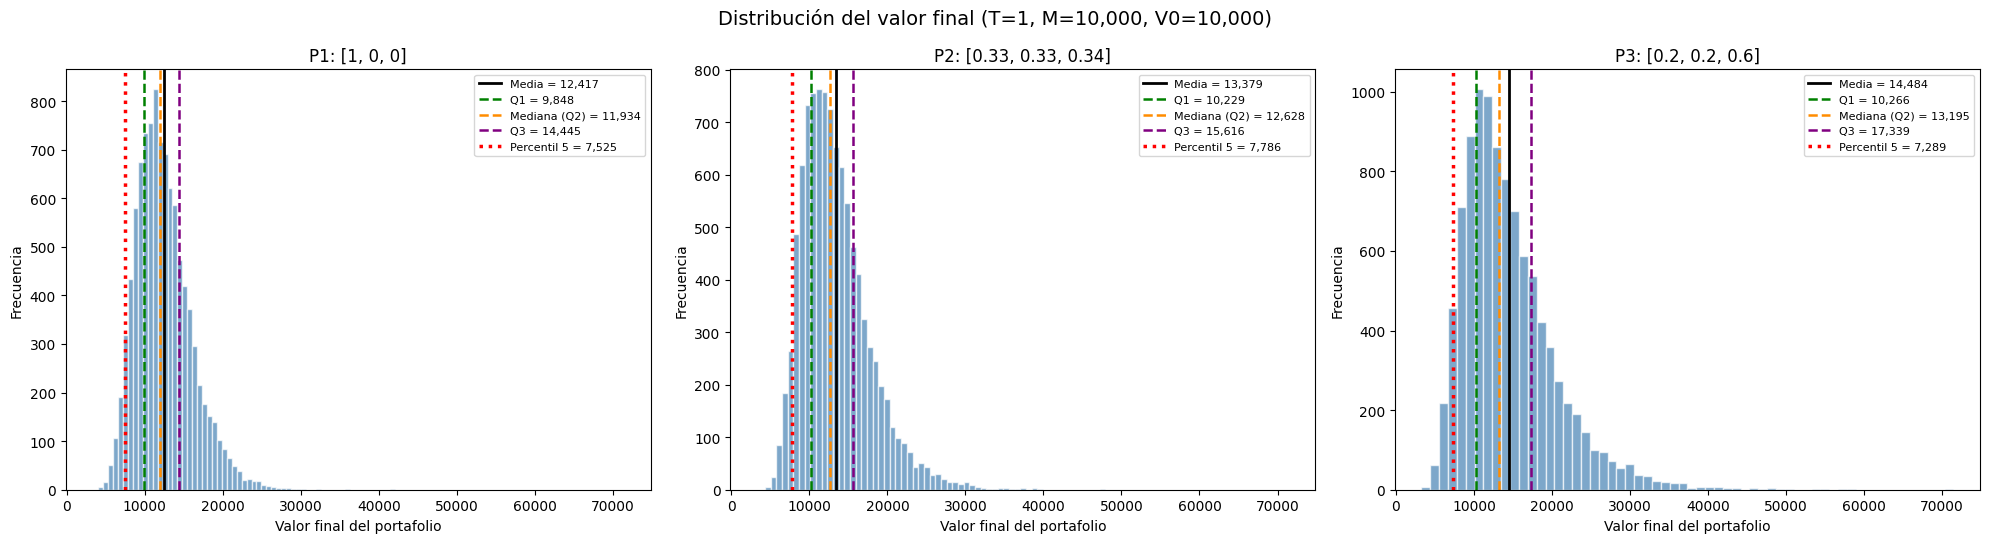

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), sharex=True)

for ax, (nombre, v) in zip(axes, valores.items()):
    # Estadísticos a marcar en el gráfico
    q1, q2, q3 = np.percentile(v, [25, 50, 75])   # cuartiles
    p5 = np.percentile(v, 5)                      # percentil 5
    media = v.mean()

    ax.hist(v, bins=60, color='steelblue', alpha=0.7, edgecolor='white')
    ax.axvline(media, color='black', lw=2, label=f'Media = {media:,.0f}')
    ax.axvline(q1, color='green', ls='--', lw=1.8, label=f'Q1 = {q1:,.0f}')
    ax.axvline(q2, color='darkorange', ls='--', lw=1.8, label=f'Mediana (Q2) = {q2:,.0f}')
    ax.axvline(q3, color='purple', ls='--', lw=1.8, label=f'Q3 = {q3:,.0f}')
    ax.axvline(p5, color='red', ls=':', lw=2.5, label=f'Percentil 5 = {p5:,.0f}')
    ax.set_title(nombre)
    ax.set_xlabel('Valor final del portafolio')
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=8)

plt.suptitle(f'Distribución del valor final (T={T}, M={M:,}, V0={V0:,})', fontsize=14)
plt.tight_layout()
plt.show()

## 5. VaR y CVaR al 95%

- **VaR 95%** = $V_0 - P_5$ (pérdida mínima en el 5% peor de los escenarios).
- **CVaR 95%** = $V_0 - E[V_T \mid V_T \le P_5]$ (pérdida promedio dentro de ese 5% peor).

Valores positivos = pérdida; negativos = incluso el percentil 5 queda por encima de $V_0$.

El CVaR siempre es mayor o igual al VaR porque promedia las pérdidas de la cola, que están todas más allá del umbral del VaR.

In [6]:
filas = []
for nombre, v in valores.items():
    p5 = np.percentile(v, 5)             # valor que deja al 5% de los escenarios por debajo
    var95 = V0 - p5                      # VaR: pérdida en el umbral del percentil 5
    cvar95 = V0 - v[v <= p5].mean()      # CVaR: pérdida promedio en los escenarios <= percentil 5
    filas.append({
        'Portafolio': nombre,
        'Valor medio': v.mean(),
        'Percentil 5': p5,
        'VaR 95%': var95,
        'VaR 95% (% de V0)': 100 * var95 / V0,
        'CVaR 95%': cvar95,
        'CVaR 95% (% de V0)': 100 * cvar95 / V0,
    })

# Tabla comparativa de riesgo entre los tres portafolios
tabla_riesgo = pd.DataFrame(filas).set_index('Portafolio').round(2)
tabla_riesgo

,Valor medio,Percentil 5,VaR 95%,VaR 95% (% de V0),CVaR 95%,CVaR 95% (% de V0)
Portafolio,,,,,,
"P1: [1, 0, 0]",12416.69,7524.69,2475.31,24.75,3302.20,33.02
"P2: [0.33, 0.33, 0.34]",13379.40,7786.08,2213.92,22.14,3071.95,30.72
"P3: [0.2, 0.2, 0.6]",14483.70,7288.88,2711.12,27.11,3612.34,36.12


## 6. Conclusiones

- El portafolio P3 (20% AAPL, 20% MSFT, 60% NVDA) tiene el mayor valor medio, 14,484, frente a 13,379 de P2 y 12,417 de P1, que equivale a una ganancia esperada de casi 45%, 34% y 24% sobre los 10,000 iniciales. También es el más disperso: su desviación estándar es 6,030, contra 4,401 de P2 y 3,569 de P1.

- El portafolio P2, el más diversificado, es el que tiene menor VaR 95%, de 2,214 (22.1% de V₀), y menor CVaR, de 3,072 (30.7%). Esto es el efecto de la diversificación: P2 pierde menos que P1 en el 5% peor de los casos y además tiene un valor medio más alto, porque combina activos que no se mueven perfectamente juntos. P1, con todo en un solo activo, tiene un VaR de 2,475 (24.8%) y un CVaR de 3,302 (33.0%). P3 es el más riesgoso en la cola, con un VaR de 2,711 (27.1%) y un CVaR de 3,612 (36.1%), porque concentra 60% en NVDA, el activo más volátil.

- En cuanto a CVaR, en el P1 se supera al VaR en unos 827, 858 en P2 y 901 en P3, es decir, entre 1.33 y 1.39 veces el VaR. Esto significa que, cuando se rebasa el umbral del percentil 5, la pérdida promedio es aproximadamente 800 a 900 más que el umbral mismo.



Porque utilizamos VaR y CVaR, El VaR 95% responde “¿cuánto puedo perder, como mínimo, en el 5% de los peores escenarios?”.El VaR solo marca dónde empieza la cola y no dice qué tan grave es lo que ocurre después. El CVaR llena ese hueco, porque promedia las pérdidas dentro de ese 5% peor. En estee ejercicio asumimos normalidad, parámetros constantes y que los últimos 5 años representan el futuro, por lo que probablemente se subestiman los eventos extremos (crisis, caídas bruscas).